# 01 — EDA: Credit Card Transactions (Sparkov)

Data: Kaggle `kartik2112/fraud-detection` — simulated transactions.

**Rule:** questions 3–6 are answered on **train only**. Test is our holdout "future" — if we look at it now, our feature decisions would leak information from it.

In [52]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("../data/raw")  # notebook lives in notebooks/, data in data/raw/

# index_col=0: the first column in the cs v is an old unnamed index
train = pd.read_csv(DATA / "fraudTrain.csv", index_col=0)
test = pd.read_csv(DATA / "fraudTest.csv", index_col=0)

# time comes as text -> convert to real datetime once, here
for df in (train, test):
    df["trans_date_trans_time"] = pd.to_datetime(df["trans_date_trans_time"])

train.shape, test.shape

((1296675, 22), (555719, 22))

In [53]:
train.head()

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,36.0788,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,48.8878,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,42.1808,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,46.2306,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,38.4207,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0


In [54]:
train.dtypes

trans_date_trans_time    datetime64[us]
cc_num                            int64
merchant                            str
category                            str
amt                             float64
first                               str
last                                str
gender                              str
street                              str
city                                str
state                               str
zip                               int64
lat                             float64
long                            float64
city_pop                          int64
job                                 str
dob                                 str
trans_num                           str
unix_time                         int64
merch_lat                       float64
merch_long                      float64
is_fraud                          int64
dtype: object

## Q1. How many rows, what % is fraud?

In [55]:
for name, df in [("train", train), ("test", test)]:
    rate = df["is_fraud"].mean()  # mean of 0/1 column = share of 1s
    print(f"{name}: {len(df):,} rows | fraud {df['is_fraud'].sum():,} = {rate:.2%}")

train: 1,296,675 rows | fraud 7,506 = 0.58%
test: 555,719 rows | fraud 2,145 = 0.39%


Fraud is rare: 0.58% of transactions in train and 0.39% in test. With this imbalance,
accuracy is misleading — a model that predicts "not fraud" for everything would score
over 99%. We evaluate with precision, recall and PR-AUC instead. The fraud rate is also
lower in the test period, so the model must cope with a shifting base rate.

## Q2. What period does each set cover?

In [56]:
for name, df in [("train", train), ("test", test)]:
    t = df["trans_date_trans_time"]
    print(f"{name}: {t.min()}  ->  {t.max()}")

train: 2019-01-01 00:00:18  ->  2020-06-21 12:13:37
test: 2020-06-21 12:14:25  ->  2020-12-31 23:59:34


The test set starts right after the training set ends (21 June 2020), so the split is
already time-based. We keep it that way: random shuffling would let the model learn
from the future and overstate its performance.

## Q3. Amount: fraud vs normal (train)

In [57]:
train.groupby("is_fraud")["amt"].agg(["mean", "median", "count"]).round(2)

,mean,median,count
is_fraud,,,
0,67.67,47.28,1289169
1,531.32,396.50,7506


Fraudulent transactions are about 8x larger: mean $531.32 vs $67.67 for legitimate ones
(median $396.50 vs $47.28). Amount will be a strong feature, especially relative to
the cardholder's usual spending.

## Q4. Top-5 categories by fraud **rate** (train)

In [58]:
by_cat = (
    train.groupby("category")["is_fraud"]
    .agg(fraud_rate="mean", n="count")   # rate AND size: a high rate on 10 rows means nothing
    .sort_values("fraud_rate", ascending=False)
)
by_cat["fraud_rate"] = (by_cat["fraud_rate"] * 100).round(2)  # in %
by_cat.head(5)

,fraud_rate,n
category,,
shopping_net,1.76,97543
misc_net,1.45,63287
grocery_pos,1.41,123638
shopping_pos,0.72,116672
gas_transport,0.47,131659


The highest fraud rates are in shopping_net (1.76%), misc_net (1.45%) and grocery_pos
(1.41%) — roughly 2.5–3x the overall rate. Two of the top three are "_net" categories:
online, card-not-present purchases, where a fraudster only needs the card details.

## Q5. Fraud rate by hour of day (train)

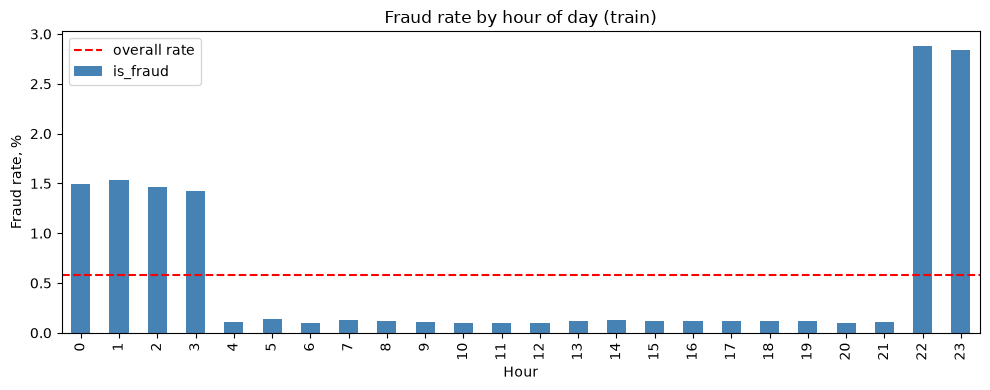

hour
22    2.88
23    2.84
1     1.53
0     1.49
2     1.47
Name: is_fraud, dtype: float64

In [59]:
train["hour"] = train["trans_date_trans_time"].dt.hour
by_hour = train.groupby("hour")["is_fraud"].mean() * 100

ax = by_hour.plot(kind="bar", figsize=(10, 4), color="steelblue")
ax.axhline(train["is_fraud"].mean() * 100, color="red", linestyle="--", label="overall rate")
ax.set(title="Fraud rate by hour of day (train)", xlabel="Hour", ylabel="Fraud rate, %")
ax.legend()
plt.tight_layout()
plt.show()

by_hour.round(2).sort_values(ascending=False).head(5)

Fraud is concentrated at night: at 22:00–23:00 the fraud rate is ~2.9% (5x the average),
and 00:00–03:00 stays around 1.5%, while daytime hours sit near 0.1%. Hour of day, or a
"night" flag, will be one of the strongest features. The pattern is unusually sharp,
which likely reflects how the synthetic data was generated — a real-world model
should not rely on it this heavily.

## Q6. Cards: how many, transactions per card (train)

In [60]:
n_cards = train["cc_num"].nunique()
per_card = train.groupby("cc_num").size()

print(f"Unique cards: {n_cards:,}")
print(f"Transactions per card: mean {per_card.mean():.0f}, median {per_card.median():.0f}, "
      f"min {per_card.min()}, max {per_card.max()}")

Unique cards: 983
Transactions per card: mean 1319, median 1054, min 7, max 3123


983 unique cards with ~1,300 transactions each on average (median 1,054, min 7) over
18 months — enough history per card to build behavioural features such as "amount vs
this card's usual amount" and "transactions in the last hour".

## Summary → feature ideas

1. amt and log(amt)
2. amt relative to the card's past average spend
3. hour and an is_night flag (22:00–03:59)
4. category, plus an is_online flag (categories ending in "_net")
5. velocity: transactions by the same card in the last 1h / 24h
6. distance between cardholder home and merchant
7. cardholder age from dob

Per-card features (2, 5) must use only transactions BEFORE the current one —
otherwise the model sees the future.

In [61]:
train['dob'] = pd.to_datetime(train['dob'])
train['age'] = train["trans_date_trans_time"] - train['dob']

train.drop(columns=['age'], axis=0)

,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,city,...,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud,hour
0,2019-01-01 00:00:18,2703186189652095,"fraud_Rippin, Kub and Mann",misc_net,4.97,Jennifer,Banks,F,561 Perry Cove,Moravian Falls,...,-81.1781,3495,"Psychologist, counselling",1988-03-09,0b242abb623afc578575680df30655b9,1325376018,36.011293,-82.048315,0,0
1,2019-01-01 00:00:44,630423337322,"fraud_Heller, Gutmann and Zieme",grocery_pos,107.23,Stephanie,Gill,F,43039 Riley Greens Suite 393,Orient,...,-118.2105,149,Special educational needs teacher,1978-06-21,1f76529f8574734946361c461b024d99,1325376044,49.159047,-118.186462,0,0
2,2019-01-01 00:00:51,38859492057661,fraud_Lind-Buckridge,entertainment,220.11,Edward,Sanchez,M,594 White Dale Suite 530,Malad City,...,-112.2620,4154,Nature conservation officer,1962-01-19,a1a22d70485983eac12b5b88dad1cf95,1325376051,43.150704,-112.154481,0,0
3,2019-01-01 00:01:16,3534093764340240,"fraud_Kutch, Hermiston and Farrell",gas_transport,45.00,Jeremy,White,M,9443 Cynthia Court Apt. 038,Boulder,...,-112.1138,1939,Patent attorney,1967-01-12,6b849c168bdad6f867558c3793159a81,1325376076,47.034331,-112.561071,0,0
4,2019-01-01 00:03:06,375534208663984,fraud_Keeling-Crist,misc_pos,41.96,Tyler,Garcia,M,408 Bradley Rest,Doe Hill,...,-79.4629,99,Dance movement psychotherapist,1986-03-28,a41d7549acf90789359a9aa5346dcb46,1325376186,38.674999,-78.632459,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1296670,2020-06-21 12:12:08,30263540414123,fraud_Reichel Inc,entertainment,15.56,Erik,Patterson,M,162 Jessica Row Apt. 072,Hatch,...,-112.4777,258,Geoscientist,1961-11-24,440b587732da4dc1a6395aba5fb41669,1371816728,36.841266,-111.690765,0,12
1296671,2020-06-21 12:12:19,6011149206456997,fraud_Abernathy and Sons,food_dining,51.70,Jeffrey,White,M,8617 Holmes Terrace Suite 651,Tuscarora,...,-77.5101,100,"Production assistant, television",1979-12-11,278000d2e0d2277d1de2f890067dcc0a,1371816739,38.906881,-78.246528,0,12
1296672,2020-06-21 12:12:32,3514865930894695,fraud_Stiedemann Ltd,food_dining,105.93,Christopher,Castaneda,M,1632 Cohen Drive Suite 639,High Rolls Mountain Park,...,-105.8189,899,Naval architect,1967-08-30,483f52fe67fabef353d552c1e662974c,1371816752,33.619513,-105.130529,0,12
1296673,2020-06-21 12:13:36,2720012583106919,"fraud_Reinger, Weissnat and Strosin",food_dining,74.90,Joseph,Murray,M,42933 Ryan Underpass,Manderson,...,-102.5411,1126,Volunteer coordinator,1980-08-18,d667cdcbadaaed3da3f4020e83591c83,1371816816,42.788940,-103.241160,0,12


In [62]:
train.columns

Index(['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt',
       'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat',
       'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat',
       'merch_long', 'is_fraud', 'hour', 'age'],
      dtype='str')

In [64]:
import sys
sys.path.append("..")   # notebook runs from notebooks/, app/ lives one level up

import importlib
import app.features as f
importlib.reload(f)     # notebook caches old imports — reload after editing the file

sample = f.build_features(train.head(1000))
sample[f.FEATURE_COLS].describe()

,amt,card_mean_amt,amt_ratio,age,hour,is_night,is_online,distance_km,txn_count_1h,txn_count_24h
count,1000.000000,439.000000,439.000000,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,78.348710,77.099432,4.480900,49.71800,5.937000,0.308000,0.254000,76.949582,0.107000,0.681000
std,113.088651,84.490396,16.105016,18.10603,3.702261,0.461898,0.435515,29.267721,0.348816,0.946644
min,1.030000,1.130000,0.003174,13.00000,0.000000,0.000000,0.000000,1.197327,0.000000,0.000000
25%,19.865000,32.645000,0.315292,35.00000,3.000000,0.000000,0.000000,57.174186,0.000000,0.000000
50%,58.970000,58.136667,0.896078,48.00000,6.000000,0.000000,0.000000,78.555667,0.000000,0.000000
75%,93.187500,92.435000,1.981547,62.00000,9.000000,1.000000,1.000000,99.831067,0.000000,1.000000
max,1636.870000,822.720000,191.000000,92.00000,12.000000,1.000000,1.000000,146.671341,3.000000,6.000000
